# Synthetic-trained context-aware sMOA

This is a **smoke demonstration**, using independent synthetic training/validation/check/background roles and the unchanged full original reference. It illustrates six observations of a hypothetical new disease. The hypothetical counts are an interface example, not a real dataset. The policy can legitimately select rho=0; then final forecasts are exactly original sMOA.

Training is synthetic-only. Raw and normalized validation MAE, safeguards, and the predeclared 1% improvement requirement determine whether a learned policy is promoted. No COVID outcomes are used to fit or select it. This is inspired by epiFFORMA's rank-conditioned concept, not an exact implementation of that multi-model system.

In [1]:
from pathlib import Path
import sys, json, joblib
ROOT=Path.cwd()
if not (ROOT/'configs/experiments.json').exists(): ROOT=ROOT.parent
sys.path.insert(0,str(ROOT))
from experiments.robust.pipeline import load_config,run
from experiments.robust.data import load_reference
from experiments.robust.policy import candidate_features,FEATURES
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display
config=load_config(ROOT/'configs/experiments.json')
RUN=run(config,experiment='policy',smoke=True)
policy=joblib.load(RUN/'policy.joblib')
frozen=json.loads((RUN/'selected_policy.json').read_text())
engine,_,_=load_reference(config)
history=np.array([10.,14.,17.,22.,31.,40.])
original=engine.match(history).baseline
final,details=policy.forecast(engine,history,frozen['rho'])
unblended=policy.forecast(engine,history,1.)[0]
print('Hypothetical observations:',history)
print('Frozen smoke policy:', {k:frozen[k] for k in ['depth','rho','selected_on']})
display(pd.DataFrame(details['candidates'],columns=['lower cumulative Q25','exact original','upper cumulative Q75'],index=range(1,5)))
display(pd.DataFrame(details['ordering'],columns=['lowest identity','middle identity','highest identity']))
display(pd.DataFrame(details['probabilities'],columns=['lowest weight','middle weight','highest weight']))

/Users/nguyentranglinh/infectious-disease-forecasting/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Complete policy: /Users/nguyentranglinh/infectious-disease-forecasting/outputs/robust_smoa/context_policy/smoke_77f27b67b2540044


Hypothetical observations: [10. 14. 17. 22. 31. 40.]
Frozen smoke policy: {'depth': 3, 'rho': 0.0, 'selected_on': 'synthetic_validation_only'}


,lower cumulative Q25,exact original,upper cumulative Q75
1,43.0,55.0,81.00
2,49.0,75.0,150.00
3,54.0,99.5,254.75
4,60.0,127.5,412.00


,lowest identity,middle identity,highest identity
0,0,1,2
1,0,1,2
2,0,1,2
3,0,1,2


,lowest weight,middle weight,highest weight
0,0.289507,0.199233,0.511260
1,0.261136,0.196712,0.542153
2,0.165441,0.149352,0.685207
3,0.156731,0.145750,0.697519


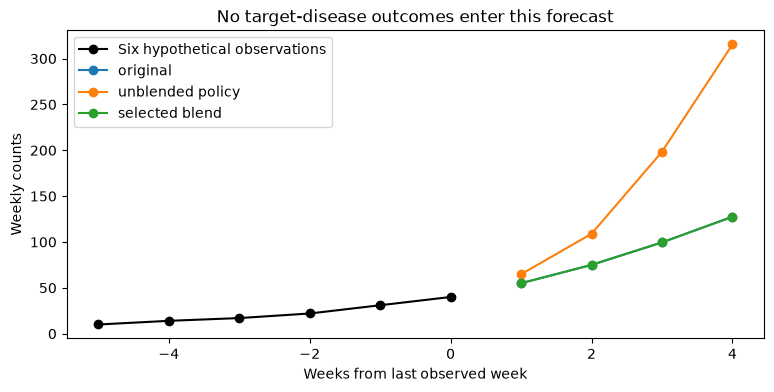

Rank identities: 0=lower quantile, 1=original sMOA, 2=upper quantile.
The original candidate may occupy any rank.


In [2]:
fig,ax=plt.subplots(figsize=(9,4))
ax.plot(range(-5,1),history,'ko-',label='Six hypothetical observations')
for label,value in [('original',original),('unblended policy',unblended),('selected blend',final)]:
    ax.plot(range(1,5),value,'o-',label=label)
ax.set(xlabel='Weeks from last observed week',ylabel='Weekly counts',title='No target-disease outcomes enter this forecast')
ax.legend();plt.show()
print('Rank identities: 0=lower quantile, 1=original sMOA, 2=upper quantile.')
print('The original candidate may occupy any rank.')

The next explanations use this same hypothetical history. TreeSHAP explains a classifier probability for a forecast rank, not the final count forecast. Kernel SHAP explains the actual final count and final-minus-original, recomputing preprocessing and matching for every changed history. Its backgrounds are independent synthetic windows scaled only with the hypothetical observed mean. Correlated weeks and hybrid histories limit interpretation; neither explanation is causal.

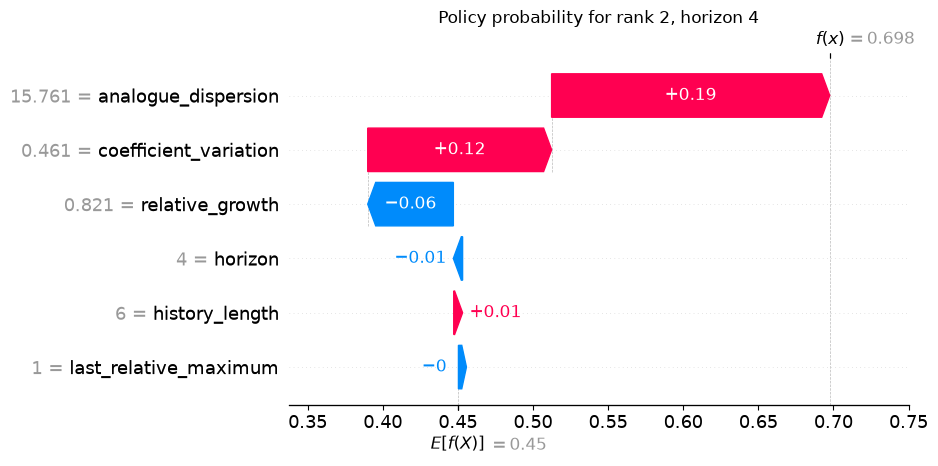

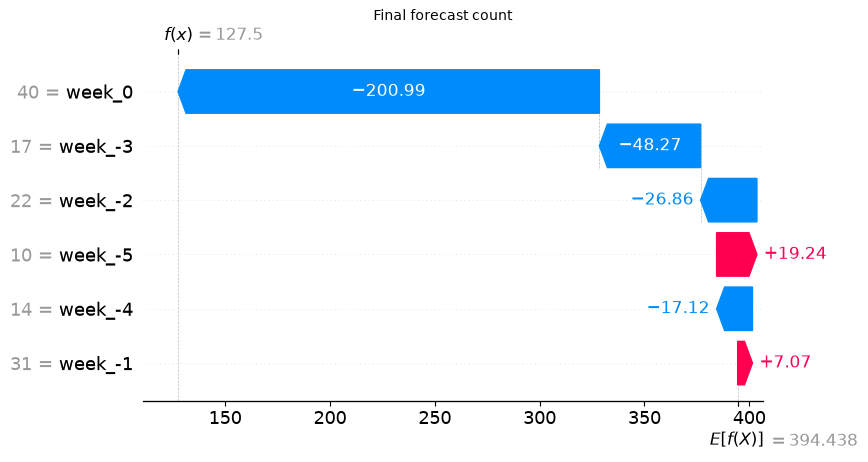

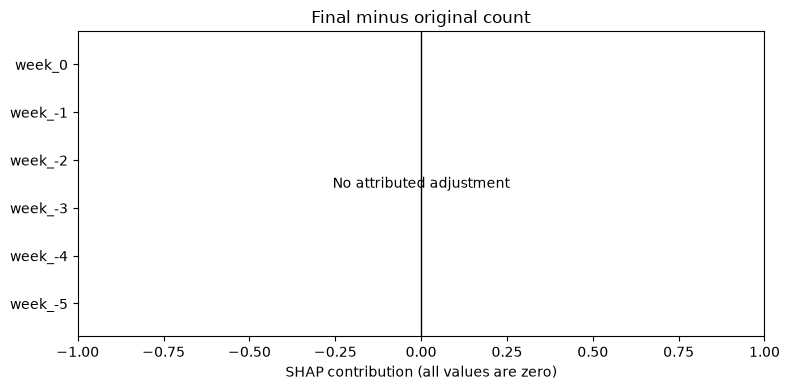

In [3]:
import shap
from experiments.robust.explain import DirectForecast,background_histories,plot_explanation
from bank import load_packed
x=candidate_features(engine,history)[0]
e=shap.TreeExplainer(policy.model)(x)
column=int(np.argmax(policy.model.predict_proba(x)[-1]))
rank=int(policy.model.classes_[column])
local=shap.Explanation(values=e.values[-1,:,column],base_values=e.base_values[-1,column],data=x[-1],feature_names=FEATURES)
shap.plots.waterfall(local,show=False);plt.title(f'Policy probability for rank {rank}, horizon 4');plt.show()
identity=json.loads((RUN/'run_config.json').read_text())
folder=Path(identity['synthetic_folder'])
meta=json.loads((folder/'metadata.json').read_text())
meta['background']=load_packed(folder/'background.npz')
bg=background_histories(meta,6,history,4,config['seed'])
wrapper=DirectForecast(engine,dict(temperature=4.,beta=0.),4,policy=policy,rho=frozen['rho'])
np.random.seed(config['seed'])
explainer=shap.KernelExplainer(wrapper,bg)
phi=np.asarray(explainer.shap_values(history[None,:],nsamples=64,l1_reg=0,silent=True))[0]
np.testing.assert_allclose(np.asarray(explainer.expected_value)+phi.sum(axis=0),wrapper(history)[0],atol=1e-6)
for output,label in enumerate(['Final forecast count','Final minus original count']):
    local=shap.Explanation(values=phi[:,output],base_values=explainer.expected_value[output],data=history,feature_names=[f'week_{i-5}' for i in range(6)])
    plot_explanation(local,label);plt.show()

The completed forecasts below are a separate retrospective evaluation, not actuals for the hypothetical sequence. M0=original, M1=previous weighted median, M2=unblended learned policy, M3=synthetically selected blend. COVID was examined during earlier project development and is not untouched confirmation. A fallback to rho=0 is a valid negative result.

In [4]:
display(pd.read_csv(RUN/'metrics.csv')[['dataset','model','n','mae','rmse','bias']])
display(pd.read_csv(RUN/'validation_selection.csv'))
display(pd.read_csv(RUN/'improved_worsened.csv'))
print('These are labelled smoke results. The full study uses 288 training and 72 fresh check curves.')
print('Frozen initial NB intervals are comparators, not target-calibrated policy uncertainty.')

,dataset,model,n,mae,rmse,bias
0,COVID19_early,M0,24,357.875000,5.952214e+02,-208.500000
1,COVID19_early,M1,24,362.625000,6.022819e+02,-217.541667
2,COVID19_early,M2,24,371.250105,6.002053e+02,-108.949721
3,COVID19_early,M3,24,357.875000,5.952214e+02,-208.500000
4,synthetic_check,M0,108,12372.476852,2.606759e+04,10475.291667
5,synthetic_check,M1,108,12242.129630,2.596104e+04,9867.629630
6,synthetic_check,M2,108,19749.379702,4.481356e+04,16606.387044
7,synthetic_check,M3,108,12372.476852,2.606759e+04,10475.291667
8,synthetic_stress,M0,432,829493.563195,2.822729e+06,-34750.334029
9,synthetic_stress,M1,432,825814.712568,2.813396e+06,-41113.439420


,depth,rho,eligible,objective,n,mae,rmse,bias,nmae,severe_underprediction
0,3,0.00,False,1.000000,108,21172.879630,49181.969528,7438.120370,2.159905,0.185185
1,3,0.25,False,0.997041,108,20823.037367,48586.615599,8156.307758,2.182812,0.194444
2,3,0.50,False,1.010901,108,20983.441664,48396.537749,8874.495146,2.226319,0.194444
3,3,1.00,False,1.060499,108,21968.035313,49240.977383,10310.869923,2.340133,0.175926
4,5,0.00,False,1.000000,108,21172.879630,49181.969528,7438.120370,2.159905,0.185185
5,5,0.25,False,0.998588,108,20872.672851,48671.234473,8209.019452,2.184431,0.194444
6,5,0.50,False,1.014172,108,21088.099442,48567.354121,8979.918534,2.229774,0.194444
7,5,1.00,False,1.067331,108,22186.128039,49580.370881,10521.716698,2.347398,0.166667


,dataset,model,improved,worsened,tied,improved_fraction,worsened_fraction,mean_absolute_error_difference
0,COVID19_early,M0,0,0,24,0.000000,0.000000,0.000000
1,COVID19_early,M1,4,12,8,0.166667,0.500000,4.750000
2,COVID19_early,M2,18,6,0,0.750000,0.250000,13.375105
3,COVID19_early,M3,0,0,24,0.000000,0.000000,0.000000
4,synthetic_check,M0,0,0,108,0.000000,0.000000,0.000000
5,synthetic_check,M1,70,20,18,0.648148,0.185185,-130.347222
6,synthetic_check,M2,38,70,0,0.351852,0.648148,7376.902850
7,synthetic_check,M3,0,0,108,0.000000,0.000000,0.000000
8,synthetic_stress,M0,0,0,432,0.000000,0.000000,0.000000
9,synthetic_stress,M1,122,227,83,0.282407,0.525463,-3678.850627


These are labelled smoke results. The full study uses 288 training and 72 fresh check curves.
Frozen initial NB intervals are comparators, not target-calibrated policy uncertainty.
